In [1]:
import numpy as np
import matplotlib.pyplot as plt

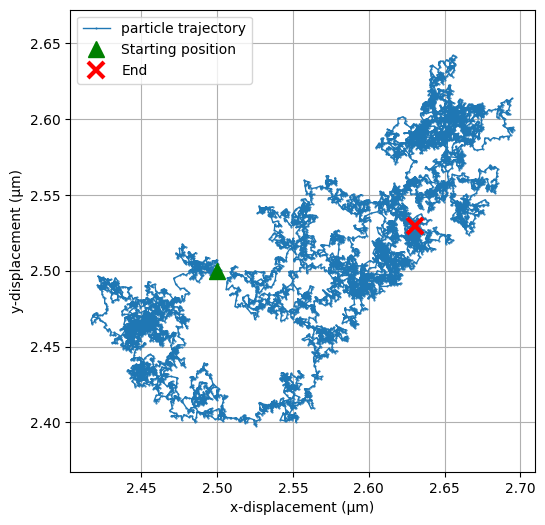

In [3]:
file_path = "dump"  # Your dump file location
timesteps = []
positions = []

with open(file_path, "r") as f:
    while True:
        try:
            line = next(f)
            if line.startswith("ITEM: TIMESTEP"):
                timestep = int(next(f).strip())
                timesteps.append(timestep)

                assert next(f).startswith("ITEM: NUMBER OF ATOMS")
                num_atoms = int(next(f).strip())

                assert next(f).startswith("ITEM: BOX BOUNDS")
                for _ in range(3): next(f)

                assert next(f).startswith("ITEM: ATOMS")
                atom_data = next(f).strip().split()
                x, y = float(atom_data[2]), float(atom_data[3])
                positions.append((x, y))

        except StopIteration:
            break

positions = np.array(positions) * 1e6  # Convert to micrometers

# Plotting
plt.figure(figsize=(6, 6))
plt.plot(positions[:, 0], positions[:, 1], marker='o', markersize=0.5, linewidth=1, label = 'particle trajectory')
plt.plot(positions[0, 0], positions[0, 1], 'g^', markersize=12, label="Starting position")
plt.plot(positions[-1, 0], positions[-1, 1], 'rx', markersize=12, markeredgewidth=3, label="End")
plt.xlabel("x-displacement (µm)")
plt.ylabel("y-displacement (µm)")
plt.legend()
plt.axis("equal")
plt.grid(True)
plt.show()